# 03 — MIST fitting for Sullivan (2024) binary stars

**Purpose:** estimate stellar properties for the binary systems downloaded and prepared in Notebook 02.

This notebook performs:
1. Joint MIST inference for both components, using their effective temperatures and radii with shared age and metallicity.
2. A simplified comparison baseline using the 1 Gyr, solar-metallicity main-sequence isochrone.

The simplified baseline is a comparison, not independent validation. This notebook does **not** make the final quality cut. Quality control and final sample saving belong in Notebook 04.

**Input**
- `data/raw/sullivan/sullivan_sample_table.csv`
- MIST isochrone files in `MIST_v1.2_vvcrit0.0_basic_isos/`

**Main output**
- `data/processed/sullivan2024_joint_and_solar_mist_comparison.csv`

Run from the project root so the relative paths resolve.


## 1. Imports, paths, and fitting configuration

Check that the MIST grid and the Sullivan sample exist before running the fit. The fitting cell below defines the model/interpolation functions and configuration.

In [1]:
# Joint MIST inference for Sullivan 2024 binary-star systems
# Fit both components using Teff + radius with shared age and [Fe/H].
# Report posterior mass estimates, joint best-fit masses, and densities.

import os
import re
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from tqdm.auto import tqdm


# ============================================================
# PATHS
# ============================================================

SULLIVAN = (
    "data/raw/sullivan/"
    "sullivan_sample_table.csv"
)

MIST_DIR = (
    "MIST_v1.2_vvcrit0.0_basic_isos"
)

OUTDIR = "data/processed"

FIGDIR = (
    "data/diagnostics/"
    "stellar_mass_ablation_final"
)

os.makedirs(
    OUTDIR,
    exist_ok=True
)

os.makedirs(
    FIGDIR,
    exist_ok=True
)


# ============================================================
# CONFIGURATION
# ============================================================

AGE_MIN_REQUESTED = 0.10
AGE_MAX_REQUESTED = 13.80

FIXED_AGE_GYR = 1.00
FEH_FIXED = 0.00

MASS_MIN = 0.10
MASS_MAX = 2.50

N_MASS = 300
N_AGE_TARGETS = 80

LARGE_SHIFT = 5.0
VERY_LARGE_SHIFT = 20.0

CHI2_GOOD = 10.0

NEAR_LOWER_MASS = 0.15


# ============================================================
# AGE TARGET GRID
# ============================================================

age_targets = np.unique(
    np.concatenate(
        [
            np.logspace(
                np.log10(
                    AGE_MIN_REQUESTED
                ),
                np.log10(
                    AGE_MAX_REQUESTED
                ),
                N_AGE_TARGETS
            ),

            [FIXED_AGE_GYR]
        ]
    )
)


# ============================================================
# LOAD SULLIVAN
# ============================================================

sample = pd.read_csv(
    SULLIVAN
)

print(
    "Sullivan sample:",
    sample.shape
)


# ============================================================
# SECONDARY RADIUS
# ============================================================

sample["Rstar2"] = (
    sample["Rstar1"]
    *
    sample["Rstar2/Rstar1"]
)

sample["e_Rstar2"] = (
    sample["Rstar2"]
    *
    np.sqrt(
        (
            sample["e_Rstar1"]
            /
            sample["Rstar1"]
        ) ** 2
        +
        (
            sample["e_Rstar2/Rstar1"]
            /
            sample["Rstar2/Rstar1"]
        ) ** 2
    )
)


# ============================================================
# FIND MIST FILES
# ============================================================

mist_files = sorted(
    glob.glob(
        os.path.join(
            MIST_DIR,
            "*.iso"
        )
    )
)

print(
    "\nMIST files found:",
    len(mist_files)
)


# ============================================================
# PARSE MIST [Fe/H]
# ============================================================

def parse_feh(filename):

    base = os.path.basename(
        filename
    )

    match = re.search(
        r"feh_([mp])(\d+(?:\.\d+)?)",
        base
    )

    if match is None:

        raise ValueError(
            "Could not parse [Fe/H] from:\n"
            f"{base}"
        )

    sign = (
        1.0
        if match.group(1) == "p"
        else -1.0
    )

    return (
        sign
        *
        float(
            match.group(2)
        )
    )


# ============================================================
# LOAD ONE MIST FILE
# ============================================================

def load_mist_iso(path):

    # --------------------------------------------------------
    # Find header
    # --------------------------------------------------------

    header = None

    with open(
        path,
        "r"
    ) as f:

        for line in f:

            if (
                line.startswith("#")
                and
                "log10_isochrone_age_yr"
                in line
            ):

                header = (
                    line[1:]
                    .strip()
                    .split()
                )

                break

    if header is None:

        raise RuntimeError(
            f"Could not find MIST header:\n{path}"
        )

    # --------------------------------------------------------
    # Read file
    # --------------------------------------------------------

    data = pd.read_csv(
        path,
        sep=r"\s+",
        comment="#",
        names=header,
        engine="python"
    )

    # --------------------------------------------------------
    # Required columns
    # --------------------------------------------------------

    required = [
        "log10_isochrone_age_yr",
        "star_mass",
        "log_Teff"
    ]

    for col in required:

        if col not in data.columns:

            raise RuntimeError(
                f"Missing column '{col}' in:\n{path}"
            )

    # --------------------------------------------------------
    # Radius
    # --------------------------------------------------------

    if "log_R" in data.columns:

        data["R"] = (
            10.0
            **
            data["log_R"]
        )

    elif "star_radius" in data.columns:

        data["R"] = (
            data["star_radius"]
        )

    elif "log_Radius" in data.columns:

        data["R"] = (
            10.0
            **
            data["log_Radius"]
        )

    else:

        raise RuntimeError(
            f"No radius column found in:\n{path}"
        )

    # --------------------------------------------------------
    # Teff
    # --------------------------------------------------------

    data["Teff"] = (
        10.0
        **
        data["log_Teff"]
    )

    # --------------------------------------------------------
    # Age [Gyr]
    # --------------------------------------------------------

    data["age_Gyr"] = (
        10.0
        **
        (
            data[
                "log10_isochrone_age_yr"
            ]
            -
            9.0
        )
    )

    # --------------------------------------------------------
    # FeH
    # --------------------------------------------------------

    data["FeH"] = parse_feh(
        path
    )

    # --------------------------------------------------------
    # Main-sequence only
    # --------------------------------------------------------

    if "phase" in data.columns:

        data = data[
            data["phase"] == 0
        ].copy()

    # --------------------------------------------------------
    # Finite
    # --------------------------------------------------------

    good = (
        np.isfinite(
            data["star_mass"]
        )
        &
        np.isfinite(
            data["Teff"]
        )
        &
        np.isfinite(
            data["R"]
        )
        &
        np.isfinite(
            data["age_Gyr"]
        )
    )

    data = data[
        good
    ].copy()

    # --------------------------------------------------------
    # Requested age range
    # --------------------------------------------------------

    data = data[
        (
            data["age_Gyr"]
            >= AGE_MIN_REQUESTED
        )
        &
        (
            data["age_Gyr"]
            <= AGE_MAX_REQUESTED
        )
    ].copy()

    return data


# ============================================================
# LOAD ALL MIST FILES
# ============================================================

mist_by_feh = {}

for path in tqdm(
    mist_files,
    desc="Loading MIST grids"
):

    feh = parse_feh(
        path
    )

    mist_by_feh[
        feh
    ] = load_mist_iso(
        path
    )


feh_values = sorted(
    mist_by_feh.keys()
)

print(
    "\nMetallicity grids:"
)

print(
    np.array(
        feh_values
    )
)


# ============================================================
# ACTUAL MIST GRID LIMITS
# ============================================================

all_ages = np.concatenate(
    [
        g["age_Gyr"].to_numpy()
        for g in mist_by_feh.values()
    ]
)

ACTUAL_AGE_MIN = (
    np.nanmin(
        all_ages
    )
)

ACTUAL_AGE_MAX = (
    np.nanmax(
        all_ages
    )
)

ACTUAL_FEH_MIN = (
    min(
        feh_values
    )
)

ACTUAL_FEH_MAX = (
    max(
        feh_values
    )
)

print(
    "\nActual MIST grid limits:"
)

print(
    f"Age : {ACTUAL_AGE_MIN:.6f}"
    f" - {ACTUAL_AGE_MAX:.6f} Gyr"
)

print(
    f"[Fe/H] : "
    f"{ACTUAL_FEH_MIN:+.2f}"
    f" - "
    f"{ACTUAL_FEH_MAX:+.2f}"
)


# ============================================================
# AGE RANGE PER METALLICITY
# ============================================================

print(
    "\nAge ranges after hard cut:"
)

for feh in feh_values:

    grid = mist_by_feh[
        feh
    ]

    print(
        f"[Fe/H]={feh:+.2f}: "
        f"{grid['age_Gyr'].min():.5f}"
        f" - "
        f"{grid['age_Gyr'].max():.5f} Gyr"
    )


# ============================================================
# GET NEAREST ACTUAL MIST ISOCHRONE
# ============================================================

def get_isochrone(
    feh,
    age_target
):

    grid = mist_by_feh[
        feh
    ]

    ages = np.sort(
        grid[
            "age_Gyr"
        ].unique()
    )

    ages = ages[
        (
            ages
            >= AGE_MIN_REQUESTED
        )
        &
        (
            ages
            <= AGE_MAX_REQUESTED
        )
    ]

    if len(ages) == 0:

        return None

    age_use = ages[
        np.argmin(
            np.abs(
                ages
                -
                age_target
            )
        )
    ]

    iso = grid[
        np.isclose(
            grid["age_Gyr"],
            age_use,
            rtol=0,
            atol=1e-8
        )
    ].copy()

    if len(iso) < 5:

        return None

    iso = (
        iso
        .sort_values(
            "star_mass"
        )
        .drop_duplicates(
            subset="star_mass"
        )
    )

    return iso


# ============================================================
# COMMON MASS GRID
# ============================================================

mass_grid = np.linspace(
    MASS_MIN,
    MASS_MAX,
    N_MASS
)


# ============================================================
# BUILD UNIQUE MIST MODEL GRID
# ============================================================

mist_models_dict = {}

print(
    "\nBuilding unique MIST model grid..."
)

for feh in tqdm(
    feh_values,
    desc="Metallicity grids"
):

    for age_target in age_targets:

        iso = get_isochrone(
            feh,
            age_target
        )

        if iso is None:
            continue

        actual_age = float(
            np.median(
                iso["age_Gyr"]
            )
        )

        key = (
            round(
                feh,
                8
            ),
            round(
                actual_age,
                8
            )
        )

        # Avoid duplicate actual isochrones
        if key in mist_models_dict:
            continue

        m = (
            iso["star_mass"]
            .to_numpy()
        )

        t = (
            iso["Teff"]
            .to_numpy()
        )

        r = (
            iso["R"]
            .to_numpy()
        )

        order = np.argsort(
            m
        )

        m = m[
            order
        ]

        t = t[
            order
        ]

        r = r[
            order
        ]

        # ----------------------------------------------------
        # Interpolate MIST onto common mass grid
        # ----------------------------------------------------

        T_model = np.interp(
            mass_grid,
            m,
            t,
            left=np.nan,
            right=np.nan
        )

        R_model = np.interp(
            mass_grid,
            m,
            r,
            left=np.nan,
            right=np.nan
        )

        valid = (
            np.isfinite(
                T_model
            )
            &
            np.isfinite(
                R_model
            )
        )

        if valid.sum() < 5:
            continue

        mist_models_dict[
            key
        ] = {

            "FeH":
                feh,

            "age_Gyr":
                actual_age,

            "Teff":
                T_model,

            "R":
                R_model,

            "valid":
                valid
        }


mist_models = list(
    mist_models_dict.values()
)

print(
    "\nUnique MIST model combinations:",
    len(mist_models)
)

print(
    "Mass grid:",
    MASS_MIN,
    "-",
    MASS_MAX,
    "Msun"
)


# ============================================================
# FIXED-AGE MODELS
# ============================================================

fixed_age_models = {}

for feh in feh_values:

    iso = get_isochrone(
        feh,
        FIXED_AGE_GYR
    )

    if iso is None:
        continue

    actual_age = float(
        np.median(
            iso["age_Gyr"]
        )
    )

    key = (
        round(
            feh,
            8
        ),
        round(
            actual_age,
            8
        )
    )

    if key in mist_models_dict:

        fixed_age_models[
            feh
        ] = mist_models_dict[
            key
        ]


if FEH_FIXED not in fixed_age_models:

    raise RuntimeError(
        "Could not construct "
        "1 Gyr, [Fe/H]=0 model."
    )

print(
    "\nFixed model:"
)

print(
    "FeH =",
    FEH_FIXED
)

print(
    "Actual MIST age =",
    fixed_age_models[
        FEH_FIXED
    ]["age_Gyr"],
    "Gyr"
)


# ============================================================
# STAR MASS POSTERIOR
# ============================================================

def star_mass_posterior(
    T_obs,
    sigma_T,
    R_obs,
    sigma_R,
    model
):

    T_model = model[
        "Teff"
    ]

    R_model = model[
        "R"
    ]

    valid = (
        model["valid"]
        .copy()
    )

    logL = np.zeros(
        len(mass_grid)
    )

    # --------------------------------------------------------
    # Teff likelihood
    # --------------------------------------------------------

    chi_T = (
        (
            T_obs
            -
            T_model
        )
        /
        sigma_T
    ) ** 2

    good_T = np.isfinite(
        chi_T
    )

    valid &= good_T

    logL += np.where(
        good_T,
        -0.5 * chi_T,
        -np.inf
    )

    # --------------------------------------------------------
    # Radius likelihood
    # --------------------------------------------------------

    chi_R = (
        (
            R_obs
            -
            R_model
        )
        /
        sigma_R
    ) ** 2

    good_R = np.isfinite(
        chi_R
    )

    valid &= good_R

    logL += np.where(
        good_R,
        -0.5 * chi_R,
        -np.inf
    )

    logL[
        ~valid
    ] = -np.inf

    if not np.any(
        np.isfinite(
            logL
        )
    ):

        return None

    # --------------------------------------------------------
    # Mass-marginalized evidence
    # --------------------------------------------------------

    logZ = logsumexp(
        logL
    )

    # --------------------------------------------------------
    # Conditional mass posterior
    # --------------------------------------------------------

    pM = np.exp(
        logL
        -
        logZ
    )

    norm = np.trapezoid(
        pM,
        mass_grid
    )

    if (
        not np.isfinite(
            norm
        )
        or
        norm <= 0
    ):

        return None

    pM /= norm

    return {
        "logZ":
            logZ,

        "pM":
            pM,

        "logL":
            logL
    }


# ============================================================
# POSTERIOR QUANTILES
# ============================================================

def posterior_quantiles(
    p,
    x,
    qs=(
        0.16,
        0.50,
        0.84
    )
):

    p = np.asarray(
        p,
        dtype=float
    )

    x = np.asarray(
        x,
        dtype=float
    )

    good = (
        np.isfinite(p)
        &
        np.isfinite(x)
        &
        (p >= 0)
    )

    p = p[
        good
    ]

    x = x[
        good
    ]

    if len(x) < 2:

        return [
            np.nan
            for _ in qs
        ]

    order = np.argsort(
        x
    )

    x = x[
        order
    ]

    p = p[
        order
    ]

    cdf = np.zeros(
        len(x)
    )

    cdf[1:] = np.cumsum(
        0.5
        *
        (
            p[1:]
            +
            p[:-1]
        )
        *
        np.diff(x)
    )

    if (
        not np.isfinite(
            cdf[-1]
        )
        or
        cdf[-1] <= 0
    ):

        return [
            np.nan
            for _ in qs
        ]

    cdf /= cdf[-1]

    return [
        np.interp(
            q,
            cdf,
            x
        )
        for q in qs
    ]


# ============================================================
# FIT ONE SCENARIO
# ============================================================

def fit_scenario(
    row,
    scenario
):

    # --------------------------------------------------------
    # Observations
    # --------------------------------------------------------

    T1 = row["Teff1"]
    eT1 = row["e_Teff1"]

    T2 = row["Teff2"]
    eT2 = row["e_Teff2"]

    R1 = row["Rstar1"]
    eR1 = row["e_Rstar1"]

    R2 = row["Rstar2"]
    eR2 = row["e_Rstar2"]

    # --------------------------------------------------------
    # Candidate evolutionary models
    # --------------------------------------------------------

    if scenario == "A":

        candidate_models = [
            fixed_age_models[
                FEH_FIXED
            ]
        ]

    elif scenario == "B":

        candidate_models = [
            m
            for m in mist_models
            if np.isclose(
                m["FeH"],
                FEH_FIXED
            )
        ]

    elif scenario == "C":

        candidate_models = [
            fixed_age_models[
                feh
            ]
            for feh in feh_values
            if feh in fixed_age_models
        ]

    elif scenario == "D":

        candidate_models = list(
            mist_models
        )

    else:

        raise ValueError(
            f"Unknown scenario: {scenario}"
        )

    # --------------------------------------------------------
    # Evaluate each evolutionary model
    # --------------------------------------------------------

    model_results = []

    for model in candidate_models:

        fit1 = star_mass_posterior(
            T1,
            eT1,
            R1,
            eR1,
            model
        )

        fit2 = star_mass_posterior(
            T2,
            eT2,
            R2,
            eR2,
            model
        )

        if (
            fit1 is None
            or
            fit2 is None
        ):
            continue

        logpost = (
            fit1["logZ"]
            +
            fit2["logZ"]
        )

        model_results.append(
            {
                "model":
                    model,

                "fit1":
                    fit1,

                "fit2":
                    fit2,

                "logpost":
                    logpost
            }
        )

    if len(
        model_results
    ) == 0:

        return {
            "status":
                "FAIL"
        }

    # ========================================================
    # EVOLUTIONARY MODEL POSTERIOR
    # ========================================================

    logposts = np.array(
        [
            result["logpost"]
            for result
            in model_results
        ]
    )

    lognorm = logsumexp(
        logposts
    )

    weights = np.exp(
        logposts
        -
        lognorm
    )

    # ========================================================
    # POSTERIOR-MAP EVOLUTIONARY MODEL
    # ========================================================

    posterior_map_index = np.argmax(
        weights
    )

    posterior_map_result = (
        model_results[
            posterior_map_index
        ]
    )

    posterior_map_model = (
        posterior_map_result[
            "model"
        ]
    )

    # ========================================================
    # MARGINAL MASS POSTERIORS
    # ========================================================

    pM1 = np.zeros(
        len(mass_grid)
    )

    pM2 = np.zeros(
        len(mass_grid)
    )

    for weight, result in zip(
        weights,
        model_results
    ):

        pM1 += (
            weight
            *
            result[
                "fit1"
            ]["pM"]
        )

        pM2 += (
            weight
            *
            result[
                "fit2"
            ]["pM"]
        )

    pM1 /= np.trapezoid(
        pM1,
        mass_grid
    )

    pM2 /= np.trapezoid(
        pM2,
        mass_grid
    )

    # --------------------------------------------------------
    # Quantiles
    # --------------------------------------------------------

    q1 = posterior_quantiles(
        pM1,
        mass_grid
    )

    q2 = posterior_quantiles(
        pM2,
        mass_grid
    )

    M1_16, M1_50, M1_84 = q1
    M2_16, M2_50, M2_84 = q2

    # --------------------------------------------------------
    # Marginal posterior MAP masses
    # --------------------------------------------------------

    M1_MAP_marginal = (
        mass_grid[
            np.argmax(
                pM1
            )
        ]
    )

    M2_MAP_marginal = (
        mass_grid[
            np.argmax(
                pM2
            )
        ]
    )

    # ========================================================
    # TRUE JOINT MINIMUM-CHI2 SOLUTION
    #
    # For every common (age, FeH) model:
    #
    #   find best M1
    #   find best M2
    #
    # Then choose global maximum likelihood.
    # ========================================================

    best_joint = None

    best_total_logL = -np.inf

    for result in model_results:

        logL1 = result[
            "fit1"
        ]["logL"]

        logL2 = result[
            "fit2"
        ]["logL"]

        i1 = np.argmax(
            logL1
        )

        i2 = np.argmax(
            logL2
        )

        total_logL = (
            logL1[i1]
            +
            logL2[i2]
        )

        if (
            total_logL
            >
            best_total_logL
        ):

            best_total_logL = (
                total_logL
            )

            best_joint = {
                "model":
                    result["model"],

                "M1":
                    mass_grid[i1],

                "M2":
                    mass_grid[i2],

                "logL1":
                    logL1[i1],

                "logL2":
                    logL2[i2]
            }

    # --------------------------------------------------------
    # Joint ML model
    # --------------------------------------------------------

    joint_model = (
        best_joint["model"]
    )

    M1_joint = (
        best_joint["M1"]
    )

    M2_joint = (
        best_joint["M2"]
    )

    # --------------------------------------------------------
    # Valid mass range of joint model
    # --------------------------------------------------------

    valid_mass = (
        joint_model["valid"]
    )

    joint_mass_grid = (
        mass_grid[
            valid_mass
        ]
    )

    joint_Teff = (
        joint_model["Teff"][
            valid_mass
        ]
    )

    joint_Radius = (
        joint_model["R"][
            valid_mass
        ]
    )

    # --------------------------------------------------------
    # Joint predictions
    # --------------------------------------------------------

    T1_joint = np.interp(
        M1_joint,
        joint_mass_grid,
        joint_Teff
    )

    R1_joint = np.interp(
        M1_joint,
        joint_mass_grid,
        joint_Radius
    )

    T2_joint = np.interp(
        M2_joint,
        joint_mass_grid,
        joint_Teff
    )

    R2_joint = np.interp(
        M2_joint,
        joint_mass_grid,
        joint_Radius
    )

    # ========================================================
    # NORMALIZED RESIDUALS
    # ========================================================

    res_T1 = (
        T1_joint
        -
        T1
    ) / eT1

    res_R1 = (
        R1_joint
        -
        R1
    ) / eR1

    res_T2 = (
        T2_joint
        -
        T2
    ) / eT2

    res_R2 = (
        R2_joint
        -
        R2
    ) / eR2

    # ========================================================
    # TRUE MINIMUM CHI2
    # ========================================================

    chi2_min = (
        res_T1 ** 2
        +
        res_R1 ** 2
        +
        res_T2 ** 2
        +
        res_R2 ** 2
    )

    # ========================================================
    # POSTERIOR WIDTH
    # ========================================================

    M1_width_frac = (
        M1_84
        -
        M1_16
    ) / (
        2.0
        *
        M1_50
    )

    M2_width_frac = (
        M2_84
        -
        M2_16
    ) / (
        2.0
        *
        M2_50
    )

    # ========================================================
    # MASS BOUNDARIES
    # ========================================================

    posterior_mass_boundary = (
        (
            M1_16
            <= MASS_MIN + 1e-8
        )
        or
        (
            M2_16
            <= MASS_MIN + 1e-8
        )
        or
        (
            M1_84
            >= MASS_MAX - 1e-8
        )
        or
        (
            M2_84
            >= MASS_MAX - 1e-8
        )
    )

    joint_mass_lower_boundary = (
        (
            M1_joint
            <= MASS_MIN + 1e-8
        )
        or
        (
            M2_joint
            <= MASS_MIN + 1e-8
        )
    )

    joint_mass_upper_boundary = (
        (
            M1_joint
            >= MASS_MAX - 1e-8
        )
        or
        (
            M2_joint
            >= MASS_MAX - 1e-8
        )
    )

    near_lower_mass_edge = (
        (
            M1_16
            < NEAR_LOWER_MASS
        )
        or
        (
            M2_16
            < NEAR_LOWER_MASS
        )
    )

    # ========================================================
    # AGE BOUNDARY
    #
    # Use actual MIST endpoint, not 13.8 Gyr.
    # ========================================================

    age_joint_lower_boundary = (
        np.isclose(
            joint_model["age_Gyr"],
            ACTUAL_AGE_MIN,
            atol=1e-6
        )
    )

    age_joint_upper_boundary = (
        np.isclose(
            joint_model["age_Gyr"],
            ACTUAL_AGE_MAX,
            atol=1e-6
        )
    )

    age_boundary = (
        age_joint_lower_boundary
        or
        age_joint_upper_boundary
    )

    # ========================================================
    # METALLICITY BOUNDARY
    # ========================================================

    feh_lower_boundary = (
        np.isclose(
            joint_model["FeH"],
            ACTUAL_FEH_MIN,
            atol=1e-8
        )
    )

    feh_upper_boundary = (
        np.isclose(
            joint_model["FeH"],
            ACTUAL_FEH_MAX,
            atol=1e-8
        )
    )

    feh_boundary = (
        feh_lower_boundary
        or
        feh_upper_boundary
    )

    # ========================================================
    # RETURN
    # ========================================================

    return {

        "status":
            "OK",

        # ----------------------------------------------------
        # Marginal masses
        # ----------------------------------------------------

        "M1_16":
            M1_16,

        "M1_50":
            M1_50,

        "M1_84":
            M1_84,

        "M2_16":
            M2_16,

        "M2_50":
            M2_50,

        "M2_84":
            M2_84,

        # ----------------------------------------------------
        # Marginal MAP
        # ----------------------------------------------------

        "M1_MAP_marginal":
            M1_MAP_marginal,

        "M2_MAP_marginal":
            M2_MAP_marginal,

        # ----------------------------------------------------
        # Joint ML
        # ----------------------------------------------------

        "M1_joint_MAP":
            M1_joint,

        "M2_joint_MAP":
            M2_joint,

        "FeH_joint_MAP":
            joint_model["FeH"],

        "age_joint_MAP_Gyr":
            joint_model["age_Gyr"],

        # ----------------------------------------------------
        # Posterior-MAP evolutionary model
        # ----------------------------------------------------

        "FeH_posterior_MAP":
            posterior_map_model["FeH"],

        "age_posterior_MAP_Gyr":
            posterior_map_model["age_Gyr"],

        # ----------------------------------------------------
        # Joint predictions
        # ----------------------------------------------------

        "T1_joint":
            T1_joint,

        "R1_joint":
            R1_joint,

        "T2_joint":
            T2_joint,

        "R2_joint":
            R2_joint,

        # ----------------------------------------------------
        # Joint residuals
        # ----------------------------------------------------

        "res_T1_joint":
            res_T1,

        "res_R1_joint":
            res_R1,

        "res_T2_joint":
            res_T2,

        "res_R2_joint":
            res_R2,

        # ----------------------------------------------------
        # True chi2
        # ----------------------------------------------------

        "chi2_min":
            chi2_min,

        # ----------------------------------------------------
        # Posterior widths
        # ----------------------------------------------------

        "M1_width_frac":
            M1_width_frac,

        "M2_width_frac":
            M2_width_frac,

        # ----------------------------------------------------
        # Mass boundary flags
        # ----------------------------------------------------

        "posterior_mass_boundary":
            posterior_mass_boundary,

        "joint_mass_lower_boundary":
            joint_mass_lower_boundary,

        "joint_mass_upper_boundary":
            joint_mass_upper_boundary,

        "near_lower_mass_edge":
            near_lower_mass_edge,

        # ----------------------------------------------------
        # Age boundary flags
        # ----------------------------------------------------

        "age_joint_lower_boundary":
            age_joint_lower_boundary,

        "age_joint_upper_boundary":
            age_joint_upper_boundary,

        "age_boundary":
            age_boundary,

        # ----------------------------------------------------
        # FeH boundary flags
        # ----------------------------------------------------

        "feh_lower_boundary":
            feh_lower_boundary,

        "feh_upper_boundary":
            feh_upper_boundary,

        "feh_boundary":
            feh_boundary
    }




Sullivan sample: (286, 52)

MIST files found: 15


Loading MIST grids:   0%|          | 0/15 [00:00<?, ?it/s]


Metallicity grids:
[-4.   -3.5  -3.   -2.5  -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25
  0.    0.25  0.5 ]

Actual MIST grid limits:
Age : 0.100000 - 12.589254 Gyr
[Fe/H] : -4.00 - +0.50

Age ranges after hard cut:
[Fe/H]=-4.00: 0.10000 - 12.58925 Gyr
[Fe/H]=-3.50: 0.10000 - 12.58925 Gyr
[Fe/H]=-3.00: 0.10000 - 12.58925 Gyr
[Fe/H]=-2.50: 0.10000 - 12.58925 Gyr
[Fe/H]=-2.00: 0.10000 - 12.58925 Gyr
[Fe/H]=-1.75: 0.10000 - 12.58925 Gyr
[Fe/H]=-1.50: 0.10000 - 12.58925 Gyr
[Fe/H]=-1.25: 0.10000 - 12.58925 Gyr
[Fe/H]=-1.00: 0.10000 - 12.58925 Gyr
[Fe/H]=-0.75: 0.10000 - 12.58925 Gyr
[Fe/H]=-0.50: 0.10000 - 12.58925 Gyr
[Fe/H]=-0.25: 0.10000 - 12.58925 Gyr
[Fe/H]=+0.00: 0.10000 - 12.58925 Gyr
[Fe/H]=+0.25: 0.10000 - 12.58925 Gyr
[Fe/H]=+0.50: 0.10000 - 12.58925 Gyr

Building unique MIST model grid...


Metallicity grids:   0%|          | 0/15 [00:00<?, ?it/s]


Unique MIST model combinations: 645
Mass grid: 0.1 - 2.5 Msun

Fixed model:
FeH = 0.0
Actual MIST age = 1.0 Gyr


In [2]:
from pathlib import Path

sample_path = Path("data/raw/sullivan/sullivan_sample_table.csv")
mist_path = Path("MIST_v1.2_vvcrit0.0_basic_isos")

if not sample_path.exists():
    raise FileNotFoundError(f"Missing Sullivan sample: {sample_path.resolve()}")
if not mist_path.exists():
    raise FileNotFoundError(f"Missing MIST grid directory: {mist_path.resolve()}")

print("Sullivan sample:", sample_path.resolve())
print("MIST grid:", mist_path.resolve())
print("MIST isochrone files:", len(list(mist_path.glob("*.iso"))))


Sullivan sample: C:\Users\Lenovo\Downloads\Binaries\data\raw\sullivan\sullivan_sample_table.csv
MIST grid: C:\Users\Lenovo\Downloads\Binaries\MIST_v1.2_vvcrit0.0_basic_isos
MIST isochrone files: 15


In [3]:
# Run the joint model for every Sullivan binary system.
# The fitted rows are assembled and saved in the next cell.
results = []

for _, row in tqdm(
    sample.iterrows(),
    total=len(sample),
    desc="Joint MIST fits",
):
    fit = fit_scenario(row, "D")
    results.append({
        "KOI": row["KOI"],
        **{key: value for key, value in fit.items() if key != "status"},
        "fit_status": fit["status"],
    })

results_df = pd.DataFrame(results)

print("Fit rows:", len(results_df))
print("\nFit status:")
display(results_df["fit_status"].value_counts(dropna=False).to_frame("count"))


Joint MIST fits:   0%|          | 0/286 [00:00<?, ?it/s]

Fit rows: 286

Fit status:


,count
fit_status,
OK,286


In [4]:
# Assemble joint-fit results and measured properties.
results_df = pd.DataFrame(results)

observed = sample[
    ["KOI", "Rstar1", "e_Rstar1", "Rstar2", "e_Rstar2", "Teff1", "e_Teff1", "Teff2", "e_Teff2"]
].copy()

joint = observed.merge(
    results_df,
    on="KOI",
    how="inner",
    validate="one_to_one"
)

RHO_SUN = 1.408  # mean solar density, g cm^-3

for s in ["1", "2"]:
    r = pd.to_numeric(joint[f"Rstar{s}"], errors="coerce")
    er = pd.to_numeric(joint[f"e_Rstar{s}"], errors="coerce")
    m16 = pd.to_numeric(joint[f"M{s}_16"], errors="coerce")
    m50 = pd.to_numeric(joint[f"M{s}_50"], errors="coerce")
    m84 = pd.to_numeric(joint[f"M{s}_84"], errors="coerce")

    joint[f"rho{s}_joint_gcm3"] = RHO_SUN * m50 / r**3
    frac_r = er / r
    joint[f"rho{s}_joint_err_low"] = joint[f"rho{s}_joint_gcm3"] * np.sqrt(
        ((m50 - m16) / m50)**2 + (3 * frac_r)**2
    )
    joint[f"rho{s}_joint_err_high"] = joint[f"rho{s}_joint_gcm3"] * np.sqrt(
        ((m84 - m50) / m50)**2 + (3 * frac_r)**2
    )

    invalid = (~np.isfinite(r)) | (~np.isfinite(er)) | (r <= er) | (r <= 0)
    joint.loc[invalid, [f"rho{s}_joint_gcm3", f"rho{s}_joint_err_low", f"rho{s}_joint_err_high"]] = np.nan

joint_output = os.path.join(OUTDIR, "sullivan2024_joint_mist_masses_densities.csv")
joint.to_csv(joint_output, index=False)
print(f"Saved joint-fit results: {joint_output}")
print(f"Systems: {len(joint)}")
display(joint[[
    "KOI", "M1_16", "M1_50", "M1_84", "rho1_joint_gcm3",
    "M2_16", "M2_50", "M2_84", "rho2_joint_gcm3",
    "age_joint_MAP_Gyr", "FeH_joint_MAP", "chi2_min"
]].head())


Saved joint-fit results: data/processed\sullivan2024_joint_mist_masses_densities.csv
Systems: 286


,KOI,M1_16,M1_50,M1_84,rho1_joint_gcm3,M2_16,M2_50,M2_84,rho2_joint_gcm3,age_joint_MAP_Gyr,FeH_joint_MAP,chi2_min
0,42,1.289827,1.296510,1.302818,0.700686,0.766765,0.774456,0.781993,3.046455,1.412538,0.00,0.003745
1,112,1.140198,1.165363,1.186803,1.155487,0.915699,0.937695,0.957932,2.177612,1.000000,0.00,0.008763
2,162,1.050066,1.125737,1.179713,1.265270,0.896700,0.962663,1.021623,2.028422,0.891251,0.00,0.008350
3,163,0.764319,0.862757,0.876269,2.734749,0.731140,0.814640,0.828443,2.955435,10.000000,-0.25,3.082442
4,165,0.906533,0.935768,0.962479,2.145429,0.682096,0.700600,0.720675,3.491112,1.122018,0.00,0.050892


## 2. Simplified MIST baseline: solar metallicity and fixed age

This baseline uses the `[Fe/H] = 0` MIST isochrone at 1 Gyr, selects the main-sequence phase (`phase == 0`), and interpolates mass, radius, and luminosity from effective temperature. No extrapolation is performed beyond the isochrone temperature range.

In [5]:
from scipy.interpolate import interp1d
# Locate the solar-metallicity MIST isochrone file.
solar_candidates = sorted(glob.glob(os.path.join(MIST_DIR, "*feh_p0.00*basic.iso")))
if not solar_candidates:
    raise FileNotFoundError(
        f"No solar-metallicity MIST .iso file found in {MIST_DIR!r}. "
        "Check MIST_DIR and the filename."
    )

SOLAR_MIST_FILE = solar_candidates[0]
print("Solar-metallicity MIST file:", SOLAR_MIST_FILE)

solar_grid = load_mist_iso(SOLAR_MIST_FILE)

# MIST ages are stored as log10(age in years); 1 Gyr corresponds to 9.0.
solar_age = solar_grid[
    np.isclose(solar_grid["log10_isochrone_age_yr"], 9.0)
].copy()

solar_age = solar_age[solar_age["phase"] == 0].copy()
solar_age = (
    solar_age.sort_values("log_Teff")
    .drop_duplicates(subset="log_Teff")
)

if solar_age.empty:
    raise ValueError("No main-sequence points found at 1 Gyr in the solar-metallicity MIST grid.")

logT_solar = solar_age["log_Teff"].to_numpy()
mass_solar = interp1d(
    logT_solar, solar_age["star_mass"].to_numpy(),
    bounds_error=False, fill_value=np.nan
)
radius_solar = interp1d(
    logT_solar, 10**solar_age["log_R"].to_numpy(),
    bounds_error=False, fill_value=np.nan
)
lum_solar = interp1d(
    logT_solar, 10**solar_age["log_L"].to_numpy(),
    bounds_error=False, fill_value=np.nan
)

def solar_isochrone_properties(teff):
    """Return (mass, radius, luminosity) for Teff in K; NaN outside grid."""
    if pd.isna(teff) or teff <= 0:
        return (np.nan, np.nan, np.nan)

    logT = np.log10(float(teff))
    if logT < logT_solar.min() or logT > logT_solar.max():
        return (np.nan, np.nan, np.nan)

    return (
        float(mass_solar(logT)),
        float(radius_solar(logT)),
        float(lum_solar(logT)),
    )

print("Main-sequence grid points:", len(solar_age))
print(
    "Teff range (K):",
    round(10**logT_solar.min()),
    "to",
    round(10**logT_solar.max())
)


Solar-metallicity MIST file: MIST_v1.2_vvcrit0.0_basic_isos\MIST_v1.2_feh_p0.00_afe_p0.0_vvcrit0.0_basic.iso
Main-sequence grid points: 252
Teff range (K): 3085 to 8229


In [6]:
# Apply the simplified estimate to both components.
simple = joint[["KOI", "Teff1", "Teff2", "Rstar1", "Rstar2"]].copy()

for s in ["1", "2"]:
    values = simple[f"Teff{s}"].apply(solar_isochrone_properties)
    simple[f"M{s}_solar_iso_Msun"] = values.apply(lambda v: v[0])
    simple[f"R{s}_solar_iso_Rsun"] = values.apply(lambda v: v[1])
    simple[f"L{s}_solar_iso_Lsun"] = values.apply(lambda v: v[2])

    # Density based on measured radius, for a like-for-like comparison with joint inference.
    simple[f"rho{s}_solar_iso_gcm3"] = (
        RHO_SUN * simple[f"M{s}_solar_iso_Msun"] / simple[f"Rstar{s}"]**3
    )

# Add the simplified values to the joint-fit table and save both approaches together.
comparison = joint.merge(
    simple.drop(columns=["Teff1", "Teff2", "Rstar1", "Rstar2"]),
    on="KOI",
    how="left",
    validate="one_to_one"
)

combined_output = os.path.join(OUTDIR, "sullivan2024_joint_and_solar_mist_comparison.csv")
comparison.to_csv(combined_output, index=False)

print(f"Saved combined comparison: {combined_output}")
display(comparison[[
    "KOI",
    "M1_50", "M1_solar_iso_Msun", "rho1_joint_gcm3", "rho1_solar_iso_gcm3",
    "M2_50", "M2_solar_iso_Msun", "rho2_joint_gcm3", "rho2_solar_iso_gcm3"
]].head(10))


Saved combined comparison: data/processed\sullivan2024_joint_and_solar_mist_comparison.csv


,KOI,M1_50,M1_solar_iso_Msun,rho1_joint_gcm3,rho1_solar_iso_gcm3,M2_50,M2_solar_iso_Msun,rho2_joint_gcm3,rho2_solar_iso_gcm3
0,42,1.296510,1.294106,0.700686,0.699386,0.774456,0.775751,3.046455,3.051552
1,112,1.165363,1.159845,1.155487,1.150015,0.937695,0.934592,2.177612,2.170406
2,162,1.125737,1.123569,1.265270,1.262833,0.962663,0.964719,2.028422,2.032753
3,163,0.862757,0.883326,2.734749,2.799948,0.814640,0.827778,2.955435,3.003097
4,165,0.935768,0.935117,2.145429,2.143935,0.700600,0.698699,3.491112,3.481643
5,174,0.809408,0.815024,2.953764,2.974260,0.346451,0.347065,13.874349,13.898929
6,177,1.106245,1.102945,1.341670,1.337668,1.050417,1.045123,1.563564,1.555683
7,191,0.980909,0.981196,2.012917,2.013504,0.575097,0.579333,5.355838,5.395282
8,227,0.634334,0.629198,4.326717,4.291681,0.598577,0.592511,3.813586,3.774937
9,270,1.043798,1.042952,1.610289,1.608984,1.033944,1.030814,1.629059,1.624128


## 3. Compare masses: simplified baseline vs joint inference

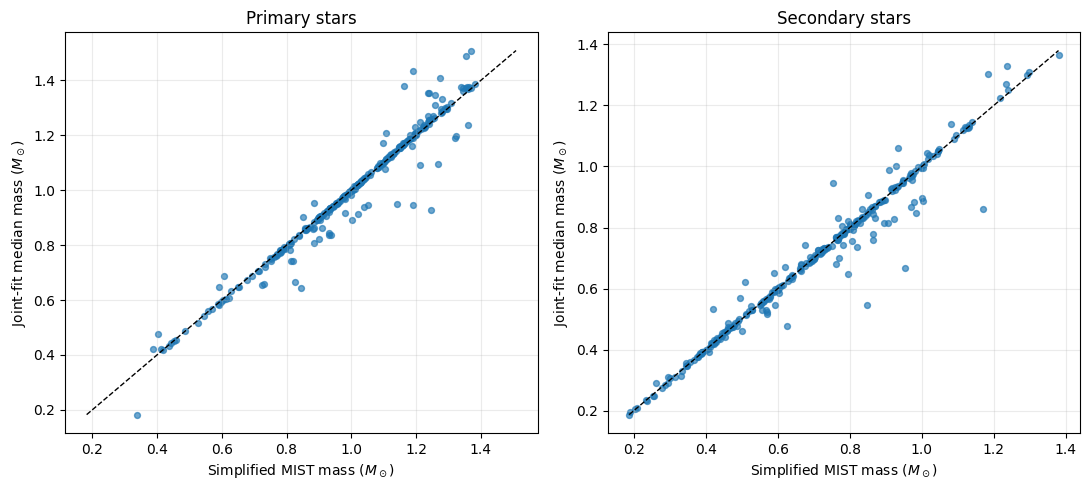

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, s, title in zip(axes, ["1", "2"], ["Primary stars", "Secondary stars"]):
    x = comparison[f"M{s}_solar_iso_Msun"]
    y = comparison[f"M{s}_50"]
    valid = np.isfinite(x) & np.isfinite(y)

    ax.scatter(x[valid], y[valid], s=18, alpha=0.65)

    if valid.any():
        lo = min(x[valid].min(), y[valid].min())
        hi = max(x[valid].max(), y[valid].max())
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)

    ax.set_xlabel(r"Simplified MIST mass ($M_\odot$)")
    ax.set_ylabel(r"Joint-fit median mass ($M_\odot$)")
    ax.set_title(title)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 4. Compare stellar-density distributions

These histograms compare central density estimates. The joint-fit density uses the joint posterior median mass and measured stellar radius; the simplified density uses the temperature-only mass estimate and the same measured radius.

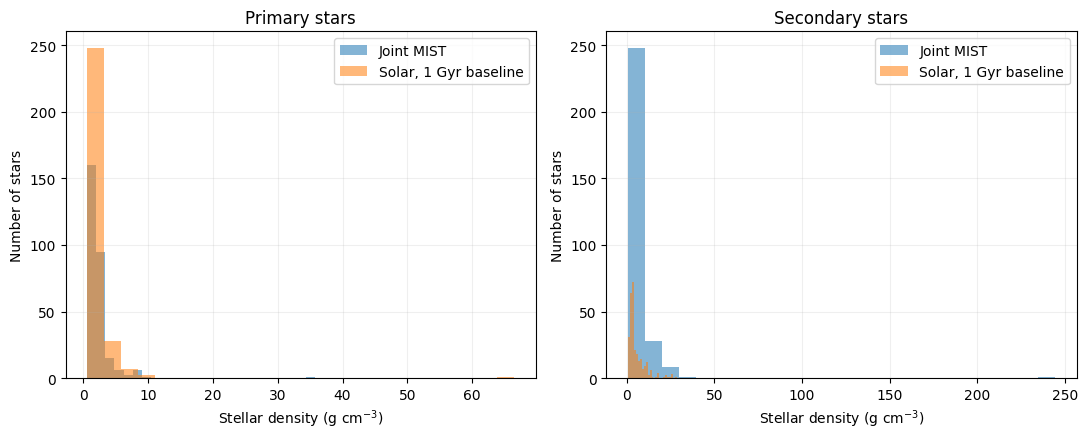

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, s, title in zip(axes, ["1", "2"], ["Primary stars", "Secondary stars"]):
    joint_rho = comparison[f"rho{s}_joint_gcm3"]
    simple_rho = comparison[f"rho{s}_solar_iso_gcm3"]

    joint_rho = joint_rho[np.isfinite(joint_rho) & (joint_rho > 0)]
    simple_rho = simple_rho[np.isfinite(simple_rho) & (simple_rho > 0)]

    ax.hist(joint_rho, bins=25, alpha=0.55, label="Joint MIST")
    ax.hist(simple_rho, bins=25, alpha=0.55, label="Solar, 1 Gyr baseline")
    ax.set_xlabel(r"Stellar density (g cm$^{-3}$)")
    ax.set_ylabel("Number of stars")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## Notes

- The joint inference uses both stars' effective temperatures and radii with shared age and metallicity.
- The simplified baseline assumes `[Fe/H] = 0` and age = 1 Gyr, and estimates mass from effective temperature alone.
- Density uses the measured radius in both methods to make the comparison consistent.
- The simplified baseline has no propagated mass uncertainty in this notebook; treat it as a central-value comparison.
- Duplicate KOI rows are not expected in the Sullivan sample table; the merge validates one row per KOI.

## Output and hand-off to Notebook 04

The combined CSV contains the fitted stellar properties and the simplified solar-metallicity baseline. Notebook 04 reads this file, applies the documented residual-based quality cut, and saves the retained and excluded system lists.

Before proceeding, verify:
- the fit ran for all input systems;
- `fit_status` counts are sensible;
- the output file exists at `data/processed/sullivan2024_joint_and_solar_mist_comparison.csv`.

Do not remove systems manually in this notebook.
